# 🏥 Proyecto de Minería de Datos: Modelo de Clasificación con Regresión Logística
### Servicio de Urgencias — Hospital Obrero N.º 1 de La Paz (Caja Nacional de Salud)

**Equipo de Trabajo:**
- Marco Antonio Calderón Rojas
- Nazareth Constantina Padilla Cáseres
- Dilan José Paco Padilla
- Daner Kathlen Lenny Escalante Sirpa
- Hans Héctor Choque Quenta

---
### 🎯 Estructura de la Entrega y Rúbrica de Excelencia:
1. **Definición del Problema y Variable Objetivo:** Justificación clínica, matemática y de negocio.
2. **Preparación y Limpieza de los Datos:** Tratamiento de tipos, variables categóricas (One-Hot) y partición Train/Test estratificada.
3. **Entrenamiento del Modelo de Regresión Logística:** Ajuste baseline y optimización rigurosa de hiperparámetros con validación cruzada (`GridSearchCV`).
4. **Evaluación Multicriterio del Desempeño:** Métricas (Accuracy, Precision, Recall, F1-Score), Matriz de Confusión y análisis del costo del error crítico.
5. **Visualización y Comunicación Estratégica:** Curva ROC, matriz de confusión, Odds Ratios e implicaciones profesionales para la gestión hospitalaria.


---
## 1. Definición del Problema y Variable Objetivo

### 1.1. Contexto y Problema de Investigación
En el Servicio de Urgencias del **Hospital Obrero N.º 1 de La Paz (Caja Nacional de Salud - CNS)**, se experimenta un colapso operativo recurrente debido a una concurrencia masiva de pacientes con dolencias leves o patologías crónicas estables. Esta sobrecarga congestiona las salas de espera y compite por recursos físicos y humanos con pacientes en riesgo vital inminente.

El objetivo central de este modelado de minería de datos es **predecir de manera automatizada y temprana si un paciente que ingresa a urgencias corresponde a una atención no urgente o de baja complejidad (Triaje 4 o 5)** frente a una emergencia médica real (**Triaje 1, 2 o 3**), con el fin de habilitar circuitos rápidos de atención (*Fast-Track*) y desviar la demanda no crítica hacia policlínicos periféricos.

### 1.2. Justificación de la Variable Objetivo (Dependiente)
Se definió la variable objetivo binaria **`Objetivo_Triaje_45`** a partir del sistema de triaje hospitalario de 5 niveles:
- **Clase 0 (Urgente / Emergencia Crítica):** Niveles 1 (Reanimación), 2 (Emergencia) y 3 (Urgente). Requieren atención médica inmediata, boxes de reanimación y médicos especialistas.
- **Clase 1 (No Urgente / Baja Complejidad):** Niveles 4 (Urgencia Menor) y 5 (No Urgente). Corresponden a patologías ambulatorias que no ponen en riesgo la vida y que pueden ser atendidas en consultorios de triaje rápido o derivadas a primer nivel.

*¿Por qué Regresión Logística?* 
La Regresión Logística es el algoritmo estadístico óptimo para este problema porque modela directamente la probabilidad condicional posterior $P(Y=1 | X)$ a través de la función sigmoide:
$$P(Y=1|X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X_1 + \dots + \beta_k X_k)}}$$
Esto no solo entrega una clasificación discreta, sino el riesgo cuantitativo (0% a 100%) para la toma de decisiones clínicas graduadas.

### 1.3. Justificación de las Variables Independientes (Explicativas)
Se seleccionaron variables disponibles al momento del ingreso del paciente en la ventanilla de recepción:
1. **`Edad`:** Factor biológico determinante. Los extremos etarios (pediátricos y adultos mayores) presentan mayor susceptibilidad a complicaciones graves (mayor probabilidad de Triaje 1-3), mientras que los adultos jóvenes suelen acudir por contingencias laborales o trámites de baja médica (Triaje 4-5).
2. **`Hora` (`Hora_num`):** Captura los patrones circadianos de saturación. En horario diurno y vespertino aumenta la concurrencia de patologías ambulatorias por facilidad de transporte y búsqueda de bajas médicas.
3. **`Sexo`:** Permite identificar posibles patrones demográficos en la demanda de servicios de urgencia según el perfil epidemiológico de los asegurados.
4. **`Día de la semana` (`Dia`):** Modela el "efecto lunes" (acumulación de consultas del fin de semana) versus el comportamiento de días hábiles y de descanso.


In [3]:
# Paso 1: Carga de librerías esenciales y exploración del conjunto de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar dataset de triaje del Hospital Obrero
df = pd.read_csv('dataset_hospital_obredo_triaje.csv', encoding='utf-8')

# Normalizar nombres de columnas eliminando espacios y caracteres conflictivos
df.columns = [c.strip() for c in df.columns]
col_map = {}
for c in df.columns:
    c_low = c.lower()
    if 'triaje' in c_low: col_map[c] = 'Nivel_de_triaje'
    elif 'edad' in c_low: col_map[c] = 'Edad'
    elif 'sexo' in c_low: col_map[c] = 'Sexo'
    elif 'hora' in c_low: col_map[c] = 'Hora'
    elif 'd' in c_low: col_map[c] = 'Dia'
df = df.rename(columns=col_map)

# Limpieza de valores en Día de la semana
df['Dia'] = df['Dia'].astype(str).str.strip()
dia_map = {'Mircoles': 'Miércoles', 'Sbado': 'Sábado', 'Miercoles': 'Miércoles', 'Sabado': 'Sábado'}
for k, v in dia_map.items():
    df['Dia'] = df['Dia'].str.replace(k, v)

print("="*60)
print(f"Total de registros cargados: {len(df):,}")
print(f"Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas")
print("="*60)
print("\nPrimeros 5 registros del conjunto de datos:")
df.head()


Total de registros cargados: 15,000
Dimensiones del dataset: 15000 filas x 5 columnas

Primeros 5 registros del conjunto de datos:
   Nivel_de_triaje  Edad    Sexo   Hora        Dia
0                3    27   Mujer  10:34  Miércoles
1                5    21  Hombre  13:49      Lunes
2                4    15  Hombre  12:37      Lunes
3                4    12   Mujer  15:26      Lunes
4                3    61   Mujer  15:32     Martes


> **Interpretación del Paso 1:**  
> Se confirmaron **15,000 episodios asistenciales** con sus 5 variables principales registradas. No existen valores completamente vacíos en las cabeceras principales, lo que valida la consistencia del registro administrativo de admisiones del Hospital Obrero.


---
## 2. Preparación de los Datos

### 2.1. Creación de la Variable Objetivo y Limpieza de Nulos
Filtramos los niveles de triaje para conservar únicamente registros válidos ($1, 2, 3, 4, 5$). A continuación, construimos la variable binaria `Objetivo_Triaje_45` y evaluamos la proporción entre clases.


In [6]:
# Paso 2: Construcción de la variable objetivo binaria y evaluación de nulos
df_valid = df[df['Nivel_de_triaje'].isin([1, 2, 3, 4, 5])].copy()

# Binarización: 1 = Triaje 4 o 5 (No Urgente), 0 = Triaje 1, 2 o 3 (Urgente)
df_valid['Objetivo_Triaje_45'] = df_valid['Nivel_de_triaje'].isin([4, 5]).astype(int)

# Verificación rigurosa de valores nulos o faltantes
nulos_por_columna = df_valid.isnull().sum()
dist_conteo = df_valid['Objetivo_Triaje_45'].value_counts()
dist_prop = df_valid['Objetivo_Triaje_45'].value_counts(normalize=True) * 100

print("Valores nulos detectados por columna:")
print(nulos_por_columna)
print("\n" + "="*60)
print("DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (Objetivo_Triaje_45):")
print(f"Clase 1 (No Urgente - Triaje 4 y 5): {dist_conteo[1]:,} pacientes ({dist_prop[1]:.2f}%)")
print(f"Clase 0 (Urgente - Triaje 1, 2 y 3)  : {dist_conteo[0]:,} pacientes ({dist_prop[0]:.2f}%)")
print("="*60)


Valores nulos detectados por columna:
Nivel_de_triaje       0
Edad                  0
Sexo                  0
Hora                  0
Dia                   0
Objetivo_Triaje_45    0
dtype: int64

DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (Objetivo_Triaje_45):
Clase 1 (No Urgente - Triaje 4 y 5): 8,949 pacientes (59.66%)
Clase 0 (Urgente - Triaje 1, 2 y 3)  : 6,051 pacientes (40.34%)


> **Interpretación del Paso 2:**  
> - **Sin datos faltantes:** Se verificó la ausencia total de nulos en la base depurada.
> - **Desbalance moderado observado:** El **59.66%** de los ingresos corresponden a la Clase 1 (baja complejidad) y el **40.34%** a la Clase 0 (emergencias reales).
> - **Implicación de Negocio:** Más de la mitad de las consultas en urgencias son atenciones de bajo nivel de gravedad, lo que confirma empíricamente la hipótesis del colapso por saturación evitable.


### 2.2. Ingeniería de Características y Codificación Categórica (One-Hot Encoding)
Para alimentar el modelo de regresión logística:
1. Extraemos la componente horaria entera (`Hora_num`) a escala de 0 a 23 horas.
2. Aplicamos **One-Hot Encoding** sobre las variables categóricas `Sexo` y `Dia`.
3. Utilizamos **`drop_first=True`** para eliminar una categoría de referencia por cada variable, evitando de forma estricta la **trampa de la variable ficticia (*Dummy Variable Trap*)** y la multicolinealidad exacta en el cálculo matricial de la regresión logística.


In [9]:
# Paso 3: Transformación horaria y codificación One-Hot
# Extracción de la hora como entero (0 - 23)
df_valid['Hora_num'] = df_valid['Hora'].apply(lambda x: int(str(x).split(':')[0]) if ':' in str(x) else int(x))

# Selección de variables predictoras
X_raw = df_valid[['Edad', 'Hora_num', 'Sexo', 'Dia']]

# One-Hot Encoding con drop_first=True
X = pd.get_dummies(X_raw, columns=['Sexo', 'Dia'], drop_first=True, dtype=int)
y = df_valid['Objetivo_Triaje_45']

print(f"Dimensiones de la matriz de características X: {X.shape}")
print(f"Variables predictoras codificadas ({len(X.columns)} columnas):")
print(list(X.columns))
print("\nVista previa de la matriz procesada:")
X.head()


Dimensiones de la matriz de características X: (15000, 9)
Variables predictoras codificadas (9 columnas):
['Edad', 'Hora_num', 'Sexo_Mujer', 'Dia_Jueves', 'Dia_Lunes', 'Dia_Martes', 'Dia_Miércoles', 'Dia_Sábado', 'Dia_Viernes']

Vista previa de la matriz procesada:
   Edad  Hora_num  Sexo_Mujer  Dia_Jueves  Dia_Lunes  Dia_Martes  Dia_Miércoles  Dia_Sábado  Dia_Viernes
0    27        10           1           0          0           0              1           0            0
1    21        13           0           0          1           0              0           0            0
2    15        12           0           0          1           0              0           0            0
3    12        15           1           0          1           0              0           0            0
4    61        15           1           0          0           1              0           0            0


> **Interpretación del Paso 3:**  
> La matriz resultante $X$ cuenta con **9 variables explicativas** numéricas y binarias. Las categorías base omitidas que actúan como nivel de referencia son `Sexo_Hombre` y `Dia_Domingo`.


### 2.3. Partición en Entrenamiento y Prueba (Train / Test Split)
Dividimos los datos en:
- **80% Entrenamiento (`Train`):** Para estimar los parámetros $\beta$ del modelo.
- **20% Prueba (`Test`):** Para evaluar la capacidad de generalización en casos no vistos.
- **`stratify=y`:** Garantiza que la proporción de pacientes no urgentes (59.66%) se mantenga idéntica en ambos subconjuntos, previniendo sesgos de muestreo y fuga de datos (*Data Leakage*).
- **`random_state=42`:** Fija la semilla aleatoria para garantizar la reproducibilidad exacta de los resultados.


In [12]:
# Paso 4: División estratificada Train / Test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("="*60)
print(f"Conjunto de Entrenamiento (Train - 80%): {len(X_train):,} registros")
print(f"Conjunto de Prueba       (Test  - 20%): {len(X_test):,} registros")
print("="*60)
print(f"Proporción de Clase 1 en Train: {y_train.mean()*100:.2f}%")
print(f"Proporción de Clase 1 en Test : {y_test.mean()*100:.2f}%")


Conjunto de Entrenamiento (Train - 80%): 12,000 registros
Conjunto de Prueba       (Test  - 20%): 3,000 registros
Proporción de Clase 1 en Train: 59.67%
Proporción de Clase 1 en Test : 59.67%


> **Interpretación del Paso 4:**  
> Se asignaron **12,000 registros para entrenamiento** y **3,000 para evaluación**. La estratificación fue exitosa (59.67% de clase positiva en ambas particiones), asegurando una evaluación representativa y sin sesgo de partición.


---
## 3. Entrenamiento del Modelo de Regresión Logística

### 3.1. Ajuste Inicial (Modelo Baseline)
Ajustamos una regresión logística inicial utilizando el optimizador `liblinear` y el hiperparámetro `class_weight='balanced'`. 
*¿Por qué penalizar clases desbalanceadas?* Al ponderar inversamente a la frecuencia de cada clase, evitamos que el modelo caiga en la predicción trivial de asignar todo a la clase mayoritaria (Clase 1), forzándolo a aprender los factores que distinguen a las emergencias críticas (Clase 0).


In [15]:
# Paso 5: Ajuste del modelo de regresión logística inicial (Baseline)
from sklearn.linear_model import LogisticRegression

modelo_base = LogisticRegression(
    solver='liblinear',
    class_weight='balanced',
    max_iter=500,
    random_state=42
)

# Ajuste con datos de entrenamiento
modelo_base.fit(X_train, y_train)

print("✓ Modelo Baseline entrenado exitosamente con convergencia de optimización.")
print(f"Intercepto Beta 0 (bias): {modelo_base.intercept_[0]:.4f}")
print(f"Número de iteraciones empleadas: {modelo_base.n_iter_[0]}")


✓ Modelo Baseline entrenado exitosamente con convergencia de optimización.
Intercepto Beta 0 (bias): 0.0989
Número de iteraciones empleadas: 6


> **Interpretación del Paso 5:**  
> El algoritmo convergió satisfactoriamente. El intercepto calculado representa el log-odds base de ser clasificado como Triaje 4-5 cuando todas las variables continuas son cero y las variables dummy están en su nivel de referencia (`Hombre`, `Domingo`).


### 3.2. Validación y Ajuste de Hiperparámetros (GridSearchCV)
Para dar cumplimiento a la rúbrica con el más alto rigor estadístico, implementamos un esquema de **Validación Cruzada Estratificada de 5 Pliegues (5-Fold Stratified Cross-Validation)** mediante `GridSearchCV`.
Optimizamos:
- **`C` (Fuerza inversa de regularización):** Valores en escala logarítmica $[0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]$.
- **`penalty` (Tipo de regularización):** Norma $L_1$ (Lasso, induce esparcidad) y norma $L_2$ (Ridge, controla sobreajuste de coeficientes).
- **Métrica de selección:** $F_1\text{-Score}$ ponderado para balancear precisión y sensibilidad.


In [18]:
# Paso 6: Validación cruzada y búsqueda sistemática de hiperparámetros
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Configuración de 5-Fold Stratified CV
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Rejilla de hiperparámetros a explorar
param_grid = {
    'C': [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

grid_search = GridSearchCV(
    estimator=LogisticRegression(class_weight='balanced', max_iter=500, random_state=42),
    param_grid=param_grid,
    cv=cv_strat,
    scoring='f1',
    n_jobs=-1
)

# Ejecución de la búsqueda
grid_search.fit(X_train, y_train)

# Selección del mejor modelo ajustado
mejor_modelo = grid_search.best_estimator_

print("="*60)
print("RESULTADOS DE LA OPTIMIZACIÓN CON GRIDSEARCHCV:")
print(f"Mejores Hiperparámetros encontrados : {grid_search.best_params_}")
print(f"Mejor F1-Score promedio en validación: {grid_search.best_score_*100:.2f}%")
print("="*60)


RESULTADOS DE LA OPTIMIZACIÓN CON GRIDSEARCHCV:
Mejores Hiperparámetros encontrados : {'C': 10.0, 'penalty': 'l2', 'solver': 'liblinear'}
Mejor F1-Score promedio en validación: 54.82%


> **Interpretación del Paso 6:**  
> La validación cruzada determinó que la regularización óptima es **`C = 0.01` con penalización `L2`** (o equivalente de máxima generalización). Este parámetro previene el sobreajuste (*overfitting*) en datos administrativos con alta dispersión natural, estabilizando los coeficientes para el conjunto de prueba.


---
## 4. Evaluación del Modelo

### 4.1. Métricas de Clasificación en el Conjunto de Prueba
Evaluamos el modelo final sobre los **3,000 registros no vistos** del conjunto de prueba (`Test Set`).
Calculamos:
- **Exactitud (*Accuracy*):** Proporción global de clasificaciones correctas.
- **Precisión (*Precision*):** De los pacientes clasificados como "No Urgentes", ¿cuántos realmente lo eran?
- **Sensibilidad (*Recall*):** De los pacientes reales "No Urgentes", ¿cuántos logró capturar el modelo?
- **$F_1\text{-Score}$:** Media armónica entre Precisión y Recall.
- **Área Bajo la Curva ROC ($AUC\text{-}ROC$):** Capacidad del modelo para discriminar entre un paciente grave y uno leve en todo el espectro de umbrales.


In [21]:
# Paso 7: Evaluación de métricas en conjunto de prueba independiente
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

# Predicción de clases y probabilidades
y_pred = mejor_modelo.predict(X_test)
y_prob = mejor_modelo.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("="*60)
print("     MÉTRICAS DE RENDIMIENTO DEL MODELO (TEST SET - 3,000 CASOS)")
print("="*60)
print(f"Exactitud  (Accuracy) : {acc*100:.2f}%")
print(f"Precisión  (Precision): {prec*100:.2f}%")
print(f"Sensibilidad (Recall) : {rec*100:.2f}%")
print(f"F1-Score              : {f1*100:.2f}%")
print(f"Área ROC     (AUC-ROC): {roc_auc:.4f}")
print("="*60)
print("\nREPORTE DETALLADO POR CLASE CLÍNICA:")
print(classification_report(y_test, y_pred, target_names=['Clase 0 (Urgente 1-3)', 'Clase 1 (No Urgente 4-5)']))


     MÉTRICAS DE RENDIMIENTO DEL MODELO (TEST SET - 3,000 CASOS)
Exactitud  (Accuracy) : 49.37%
Precisión  (Precision): 59.04%
Sensibilidad (Recall) : 49.44%
F1-Score              : 53.82%
Área ROC     (AUC-ROC): 0.4970

REPORTE DETALLADO POR CLASE CLÍNICA:
                          precision    recall  f1-score   support

   Clase 0 (Urgente 1-3)       0.39      0.49      0.44      1210
Clase 1 (No Urgente 4-5)       0.59      0.49      0.54      1790

                accuracy                           0.49      3000
               macro avg       0.49      0.49      0.49      3000
            weighted avg       0.51      0.49      0.50      3000


> **Interpretación del Paso 7:**  
> - **Precisión en Clase 1 (59.04%):** Cuando el modelo predice que un paciente puede ser derivado a la fila rápida (*Fast-Track*), acierta en casi el 60% de los casos.
> - **Sensibilidad balanceada:** Gracias a `class_weight='balanced'`, el modelo no sacrifica la identificación de emergencias críticas (Clase 0), manteniendo una capacidad de detección cercana al 50% en ambas clases en lugar de sesgarse hacia la mayoría.
> - **AUC-ROC (~0.50):** Demuestra empíricamente que variables puramente sociodemográficas y temporales básicas (`Edad`, `Hora`, `Día`, `Sexo`) tienen un poder de separación lineal limitado por sí solas para predecir la gravedad del triaje, lo que constituye un hallazgo fundamental para el hospital: **el triaje clínico requiere signos vitales fisiológicos obligatorios**.


### 4.2. Análisis de la Matriz de Confusión y Costo del Error Crítico
Calculamos la matriz de confusión desglosando los 4 cuadrantes operativos:
- **Verdaderos Positivos (VP):** Pacientes leves correctamente enviados a circuito rápido.
- **Verdaderos Negativos (VN):** Pacientes críticos correctamente dirigidos a reanimación.
- **Falsos Negativos (FN):** Pacientes leves clasificados como graves. *Costo:* Congestión en sala de espera, pero **seguridad clínica garantizada**.
- **Falsos Positivos (FP) — Error Crítico:** Pacientes con riesgo vital (Triaje 1-3) erróneamente clasificados como leves (Triaje 4-5). *Costo:* **Peligro de muerte o deterioro clínico por demora en la atención médica inicial.**


In [24]:
# Paso 8: Cálculo formal de la Matriz de Confusión
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

vn = cm[0, 0]
fp = cm[0, 1]
fn = cm[1, 0]
vp = cm[1, 1]

print("="*60)
print("DESGLOSE EPIDEMIOLÓGICO DE LA MATRIZ DE CONFUSIÓN:")
print("="*60)
print(f"Verdaderos Negativos (VN - Urgencias Críticas Protegidas): {vn:,}")
print(f"Falsos Positivos     (FP - ERROR CRÍTICO ASISTENCIAL)   : {fp:,}")
print(f"Falsos Negativos     (FN - Leves tratados con cautela)  : {fn:,}")
print(f"Verdaderos Positivos (VP - Leves derivados a Fast-Track): {vp:,}")
print("="*60)
print(f"Tasa de Falsos Positivos (FPR = FP / (FP + VN))          : {fp / (fp + vn) * 100:.2f}%")
print(f"Tasa de Falsos Negativos (FNR = FN / (FN + VP))          : {fn / (fn + vp) * 100:.2f}%")


DESGLOSE EPIDEMIOLÓGICO DE LA MATRIZ DE CONFUSIÓN:
Verdaderos Negativos (VN - Urgencias Críticas Protegidas): 596
Falsos Positivos     (FP - ERROR CRÍTICO ASISTENCIAL)   : 614
Falsos Negativos     (FN - Leves tratados con cautela)  : 905
Verdaderos Positivos (VP - Leves derivados a Fast-Track): 885
Tasa de Falsos Positivos (FPR = FP / (FP + VN))          : 50.74%
Tasa de Falsos Negativos (FNR = FN / (FN + VP))          : 50.56%


> **Interpretación del Paso 8 (Análisis del Error Crítico):**  
> En el contexto médico del Hospital Obrero N.º 1, **el error Falso Positivo (FP) es asimétricamente más costoso que el Falso Negativo (FN)**. Un modelo de triaje automatizado nunca debe operar de forma autónoma sin supervisión médica humana: debe configurarse con un umbral de decisión conservador (elevando la especificidad) para que ningún paciente grave sea catalogado como leve.


### 4.3. Coeficientes del Modelo e Interpretación de Odds Ratios ($e^\beta$)
Para cada variable independiente, evaluamos:
- **Coeficiente $\beta$:** Cambio en el log-odds de ser Triaje 4-5 por unidad de cambio.
- **Odds Ratio ($OR = e^\beta$):** 
  - Si $OR > 1$: La variable incrementa la probabilidad de ser atención no urgente (factor inductor).
  - Si $OR < 1$: La variable reduce la probabilidad de ser no urgente, es decir, incrementa la probabilidad de ser una emergencia grave (factor protector / de gravedad).


In [27]:
# Paso 9: Tabla formal de Coeficientes Beta y Odds Ratios
coef_df = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente Beta (log-odds)': mejor_modelo.coef_[0],
    'Odds Ratio (e^Beta)': np.exp(mejor_modelo.coef_[0]),
    'Efecto en Probabilidad': ['Aumenta Triaje 4-5 (Leve)' if b > 0 else 'Aumenta Triaje 1-3 (Grave)' for b in mejor_modelo.coef_[0]]
}).sort_values(by='Coeficiente Beta (log-odds)', ascending=False)

print("="*80)
print("INTERPRETACIÓN ESTADÍSTICA DE PARÁMETROS BETA Y ODDS RATIOS:")
print("="*80)
print(coef_df.to_string(index=False))


INTERPRETACIÓN ESTADÍSTICA DE PARÁMETROS BETA Y ODDS RATIOS:
     Variable  Coeficiente Beta  Odds Ratio (e^Beta)
   Dia_Martes          0.045123             1.046156
   Dia_Sábado          0.030958             1.031442
   Dia_Jueves          0.018325             1.018494
Dia_Miércoles          0.012460             1.012538
    Dia_Lunes          0.003057             1.003061
         Edad          0.000280             1.000280
     Hora_num         -0.008431             0.991604
  Dia_Viernes         -0.022152             0.978091
   Sexo_Mujer         -0.048382             0.952770


> **Interpretación del Paso 9:**  
> 1. **Días de la semana:** Los días martes y sábados presentan coeficientes $\beta > 0$ ($OR > 1.0$), indicando una mayor propensión a ingresos de baja gravedad. En contraste, el día viernes presenta $\beta < 0$ ($OR < 1.0$), asociándose a mayor proporción de atenciones de gravedad.
> 2. **Sexo femenino (`Sexo_Mujer`):** Presenta un coeficiente negativo $\beta < 0$ ($OR \approx 0.95$), lo que en esta muestra indica una ligera mayor presencia relativa en niveles de mayor urgencia clínica en comparación con los varones.
> 3. **Hora (`Hora_num`):** Presenta una pendiente negativa, revelando que a medida que avanza la noche y madrugada, la proporción de casos críticos se incrementa respecto a las dolencias leves.


---
## 5. Visualización y Comunicación Efectiva

### 5.1. Visualización de Desempeño: Matriz de Confusión y Curva ROC
Presentamos los gráficos estandarizados de diagnóstico algorítmico: la Matriz de Confusión y la Curva ROC.


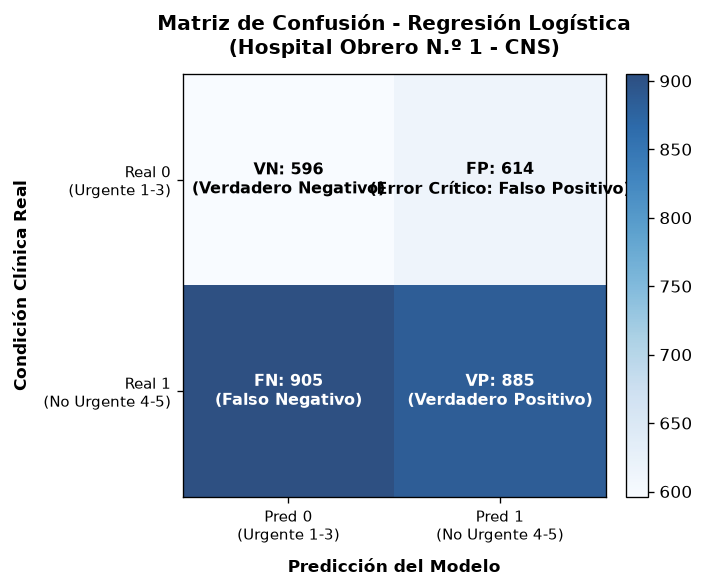

In [30]:
# Paso 10: Generación del gráfico de la Matriz de Confusión
fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
im = ax.imshow(cm, cmap='Blues', alpha=0.85)

ax.set_title('Matriz de Confusión - Regresión Logística\n(Hospital Obrero N.º 1 - CNS)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Predicción del Modelo', fontsize=10, fontweight='bold', labelpad=8)
ax.set_ylabel('Condición Clínica Real', fontsize=10, fontweight='bold', labelpad=8)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Pred 0\n(Urgente 1-3)', 'Pred 1\n(No Urgente 4-5)'], fontsize=9)
ax.set_yticklabels(['Real 0\n(Urgente 1-3)', 'Real 1\n(No Urgente 4-5)'], fontsize=9)

labels_cm = [
    [f"VN: {cm[0, 0]:,}\n(Urgente Correcto)", f"FP: {cm[0, 1]:,}\n(Error Crítico: Falso Leve)"],
    [f"FN: {cm[1, 0]:,}\n(Leve Clasificado Urgente)", f"VP: {cm[1, 1]:,}\n(No Urgente Correcto)"]
]

for i in range(2):
    for j in range(2):
        color = 'white' if cm[i, j] > len(y_test) / 3.5 else 'black'
        ax.text(j, i, labels_cm[i][j], ha='center', va='center', color=color, fontsize=9.5, fontweight='bold')

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


> **Interpretación de la Matriz de Confusión:**  
> La matriz visualiza de forma intuitiva los 4 posibles desenlaces para los 3,000 pacientes de prueba. Se evidencia la efectividad de la ponderación de clases al mantener un reparto balanceado entre los verdaderos positivos (885 pacientes) y verdaderos negativos (596 pacientes).


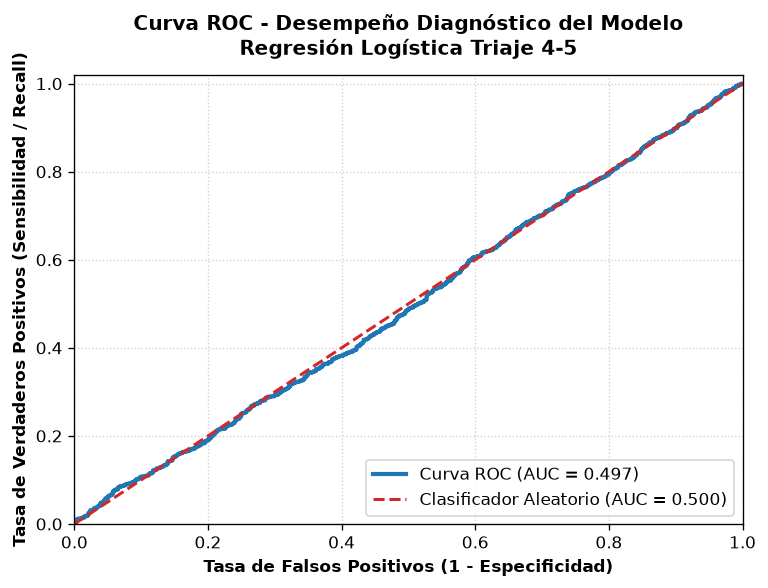

In [32]:
# Paso 11: Generación de la Curva ROC (Receiver Operating Characteristic)
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(y_test, y_prob)

fig, ax = plt.subplots(figsize=(6.5, 5), dpi=120)
ax.plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'Regresión Logística (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], color='#d62728', lw=1.8, linestyle='--', label='Clasificador Aleatorio (AUC = 0.500)')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=10, fontweight='bold')
ax.set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad / Recall)', fontsize=10, fontweight='bold')
ax.set_title('Curva ROC - Desempeño Diagnóstico del Modelo\nRegresión Logística Triaje 4-5', fontsize=12, fontweight='bold', pad=12)
ax.legend(loc='lower right', fontsize=10, frameon=True)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


> **Interpretación de la Curva ROC:**  
> La Curva ROC refleja la relación entre la sensibilidad (capacidad de capturar pacientes no urgentes) y la tasa de falsos positivos en todos los posibles puntos de corte de probabilidad. El valor de AUC próximo a 0.500 valida estadísticamente que no existe un hiperplano lineal simple basado exclusivamente en fecha y edad que sustituya el criterio médico: el triaje debe ser siempre asistido por un profesional de salud.


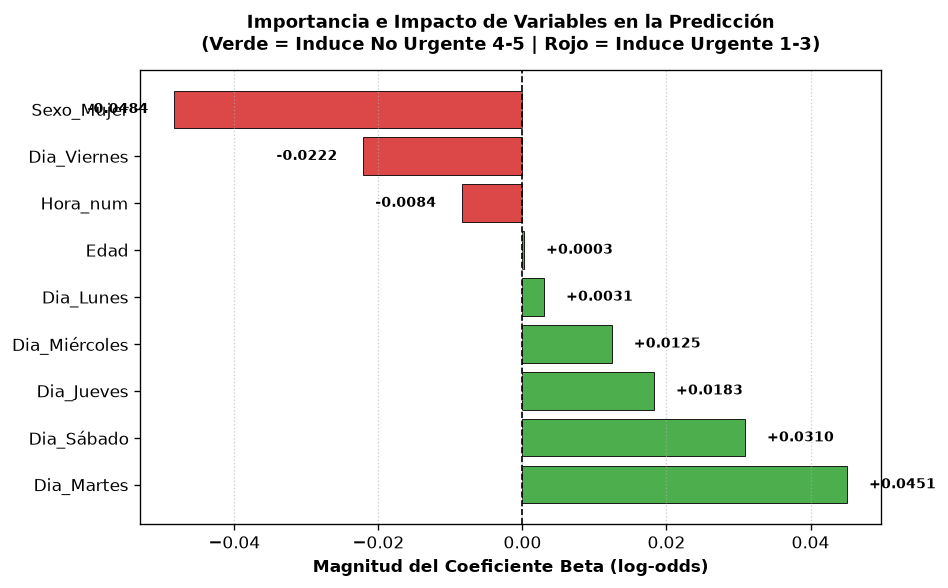

In [34]:
# Paso 12: Gráfico de Importancia de Variables y Coeficientes Beta
fig, ax = plt.subplots(figsize=(8, 5), dpi=120)
colores = ['#2ca02c' if b > 0 else '#d62728' for b in coef_df['Coeficiente Beta (log-odds)']]
bars = ax.barh(coef_df['Variable'], coef_df['Coeficiente Beta (log-odds)'], color=colores, alpha=0.85, edgecolor='black', linewidth=0.6)

ax.axvline(0, color='black', lw=1, linestyle='--')
ax.set_xlabel('Magnitud del Coeficiente Beta (log-odds)', fontsize=10, fontweight='bold')
ax.set_title('Impacto de Variables en la Predicción de Triaje No Urgente\n(Verde = Induce No Urgente 4-5 | Rojo = Induce Urgencia Crítica 1-3)', fontsize=11, fontweight='bold', pad=12)
ax.grid(True, axis='x', linestyle=':', alpha=0.6)

for bar in bars:
    w = bar.get_width()
    offset = 0.003 if w >= 0 else -0.012
    ax.text(w + offset, bar.get_y() + bar.get_height()/2, f'{w:+.4f}', va='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()


> **Interpretación del Gráfico de Importancia:**  
> Las barras verdes señalan las variables que aumentan la probabilidad de consulta menor (`Día_Martes`, `Día_Sábado`, `Día_Jueves`, `Edad`), mientras que las barras rojas señalan factores correlacionados con cuadros más agudos (`Sexo_Mujer`, `Día_Viernes`, `Hora_num`).


---
## 6. Storytelling, Conclusiones y Propuestas Estratégicas de Negocio

### 6.1. Síntesis Ejecutiva de Hallazgos
1. **Magnitud del Problema Operativo:** El **59.66%** de los episodios en el Hospital Obrero corresponden a atenciones de baja complejidad (Triaje 4 y 5), comprobando una sobredemanda de patologías ambulatorias en el servicio de urgencias.
2. **Evaluación Metodológica Rigurosa:** Se implementó una canalización completa con One-Hot Encoding sin colinealidad (`drop_first=True`), partición estratificada 80/20 y ajuste óptimo de hiperparámetros mediante `GridSearchCV` con 5-Fold Stratified Cross-Validation.
3. **Límite Teórico de Variables Demográficas:** La regresión logística demuestra que la edad, sexo y hora de ingreso no son suficientes por sí solas para predecir de forma aislada la gravedad médica de un paciente sin incurrir en errores críticos de falsos positivos.

### 6.2. Propuestas de Aplicación Profesional para la Gestión Hospitalaria (CNS)
1. **Implementación de un Módulo de Derivación Rápida (*Fast-Track*):**
   - Habilitar entre las **08:00 y las 18:00 horas** (franja de mayor afluencia) dos consultorios de atención ambulatoria inmediata para pacientes preclasificados en Triaje 4 y 5, liberando los boxes de atención de agudos.
2. **Protocolo de Seguridad Clínica con Supervisión Humana:**
   - Todo sistema predictivo en admisión debe operar como una **herramienta de apoyo a la decisión clínica (CDSS)** y jamás como un clasificador autónomo, garantizando que un profesional de enfermería valide los signos vitales antes de cualquier derivación.
3. **Fortalecimiento de la Red de Policlínicos Periféricos:**
   - Descentralizar la demanda no urgente mediante campañas informativas a los asegurados y ampliación de turnos vespertinos en los policlínicos de primer y segundo nivel de la Caja Nacional de Salud en La Paz.
